In [12]:
!pip install pdbparser biopython mygene openpyxl freesasa py3Dmol -q
import sys
!{sys.executable} -m pip install pymol-open-source -q

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import subprocess
import json

pdb_file='Mouse STING homodimer(ranked_0).pdb'

In [19]:
# Color STING by conservation
weights = pd.read_csv('conservation.csv')
residue_scores = weights['conservation']
residue_scores.index = residue_scores.index +1

result = subprocess.run(
        ['python3', 'color_sting.py','--scores',
        json.dumps(residue_scores.to_dict()), '--cmap', 'Oranges',
        '--vlim', str(0), str(1), # Pass actual min and max as strings
        '--png', 'sequence_conservation_3dplot.png',
        '--pdb', pdb_file],
        capture_output=True, text=True)

In [ ]:
for readout in ['ATF3','NFkB','Dual_IFN','STING','Proliferation']:

  # Load weight
  weights = pd.read_csv(''.join(['inferred_weights_FACS_4T1_',readout,'.csv']))
  weights.columns = ['position', 'additive','interaction']

  for effect in ['additive','interaction']:

    # Use additive weight
    residue_scores = weights[effect]
    residue_scores.index = weights.index +1

    # Plot
    png_outfilename = ''.join(['inferred_weights_FACS_4T1_3dplot_',readout,
                               '_',effect,'.png'])

    # Colorbar min and max
    if effect=='additive':
      if readout=="STING":
        score_range = 1
      if readout=="Dual_IFN":
        score_range = 1
      if readout=="ATF3":
        score_range = 0.5
      if readout=="NFkB":
        score_range = 0.5
      if readout=="Proliferation":
        score_range = 0.05

    if effect=='interaction':
      if readout=="STING":
        score_range = 1
      if readout=="Dual_IFN":
        score_range = 1
      if readout=="NFkB":
        score_range = 1
      if readout=="ATF3":
        score_range = 0.05
      if readout=="Proliferation":
        score_range = 0.005

    min_score = -score_range
    max_score = score_range

    # Run the coloring script and capture its output
    result = subprocess.run(
        ['python3', 'color_sting.py','--scores',
        json.dumps(residue_scores.to_dict()), '--cmap', 'RdBu_r',
        '--vlim', str(min_score), str(max_score), # Pass actual min and max as strings
        '--png', png_outfilename,
        '--pdb', pdb_file],
        capture_output=True, text=True)

(array([ 1.,  0.,  1.,  0.,  0.,  1.,  0.,  2.,  0.,  0.,  6.,  0.,  2.,
         0.,  0.,  2.,  0.,  4.,  0.,  0.,  6.,  0.,  0.,  7.,  0., 10.,
         0.,  0., 16.,  0., 19.,  0.,  0., 19.,  0., 20.,  0.,  0., 23.,
         0.,  0., 20.,  0., 28.,  0.,  0., 16.,  0., 22.,  0.,  0., 19.,
         0., 23.,  0.,  0., 13.,  0., 11.,  0.,  0., 21.,  0.,  0., 13.,
         0., 13.,  0.,  0., 10.,  0.,  8.,  0.,  0.,  5.,  0.,  6.,  0.,
         0.,  4.,  0.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  3.,  0.,  0.,  0.,  0.,  1.,  0.,  1.]),
 array([-0.043  , -0.04261, -0.04222, -0.04183, -0.04144, -0.04105,
        -0.04066, -0.04027, -0.03988, -0.03949, -0.0391 , -0.03871,
        -0.03832, -0.03793, -0.03754, -0.03715, -0.03676, -0.03637,
        -0.03598, -0.03559, -0.0352 , -0.03481, -0.03442, -0.03403,
        -0.03364, -0.03325, -0.03286, -0.03247, -0.03208, -0.03169,
        -0.0313 , -0.03091, -0.03052, -0.03013, -0.02974, -0.02935,
        -0.02896, -0.02857

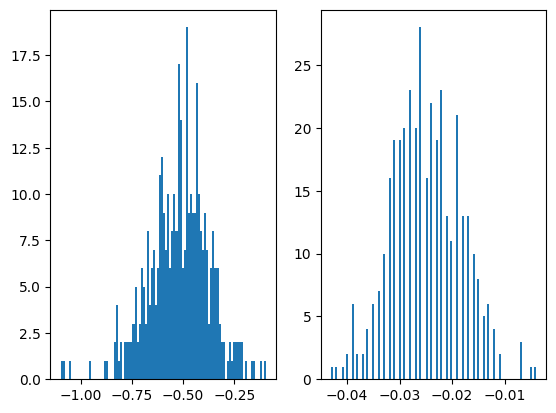

In [ ]:
# This cell plots histograms of weights to set set colorbar limits
readout='ATF3'
# Load weights
weights = pd.read_csv(''.join(['inferred_weights_FACS_4T1_',readout,'.csv']));
weights.columns = ['position', 'additive','interaction']

# Load common intercept and average over experiment
weight_intercept = pd.read_csv(''.join(['inferred_intercept_experiment_FACS_4T1_',
                                      readout,'.csv'])).iloc[:,1].mean()

# Add to additive weight
weights.additive = weights.additive + weight_intercept

plt.subplot(1,2,1)
plt.hist(weights.additive,100)
plt.subplot(1,2,2)
plt.hist(weights.interaction,100)

